# Diamond Dataset - Seaborn

## Problem Type - Regressiom
**Goal** - to predict the diamond carat 
**Target variable** - carat

**NoteBook Structure** -
    1. Importing Libraries
    2. Data Loading 
    3. Data Inspection & Quality Check
    4. EDA
    5. Feature Engineering
    6. Data Splitting / Preprocessing
    7. Model Training - ( Base Model / Primary Model)
    8. Model Evaluation
    9. Best Model

# 1. Importing Libraries
    we are going to import all the primary and secondary libraries in this section

In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    root_mean_squared_error,
)
import warnings
warnings.filterwarnings('ignore')

# 2. Data Loading
    we are going to import diamond dataset from seaborn using sns.load_dataset

In [2]:
df=sns.load_dataset('diamonds')

# 3. Data Inspection & quality check

In [3]:
print('dataset shape (row/column):',df.shape)
display(df.info())
df.head(5)

dataset shape (row/column): (53940, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype   
---  ------   --------------  -----   
 0   carat    53940 non-null  float64 
 1   cut      53940 non-null  category
 2   color    53940 non-null  category
 3   clarity  53940 non-null  category
 4   depth    53940 non-null  float64 
 5   table    53940 non-null  float64 
 6   price    53940 non-null  int64   
 7   x        53940 non-null  float64 
 8   y        53940 non-null  float64 
 9   z        53940 non-null  float64 
dtypes: category(3), float64(6), int64(1)
memory usage: 3.0 MB


None

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


In [4]:
details=pd.DataFrame({
    'dtype':df.dtypes.astype(str),
    'isnull':df.isna().sum(),
    'missing_pct %':df.isna().mean()*100,
    'unique':df.nunique()
})
details

,dtype,isnull,missing_pct %,unique
carat,float64,0,0.0,273
cut,category,0,0.0,5
color,category,0,0.0,7
clarity,category,0,0.0,8
depth,float64,0,0.0,184
table,float64,0,0.0,127
price,int64,0,0.0,11602
x,float64,0,0.0,554
y,float64,0,0.0,552
z,float64,0,0.0,375


In [6]:
df.head(5)

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


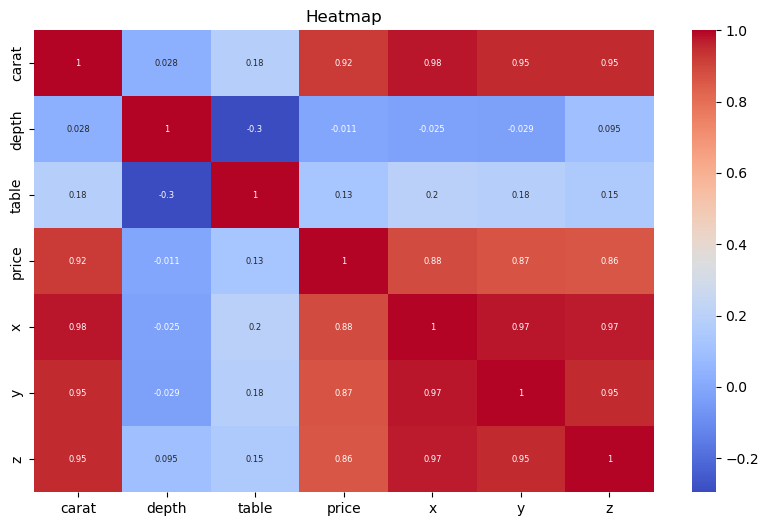

In [9]:
corr=df.corr(numeric_only=True)
plt.figure(figsize=(10,6))
sns.heatmap(
    corr,
    annot=True,
    annot_kws={'size':6},
    cmap='coolwarm'
)
plt.title("Heatmap")
plt.show()

Text(0, 0.5, 'Carat')

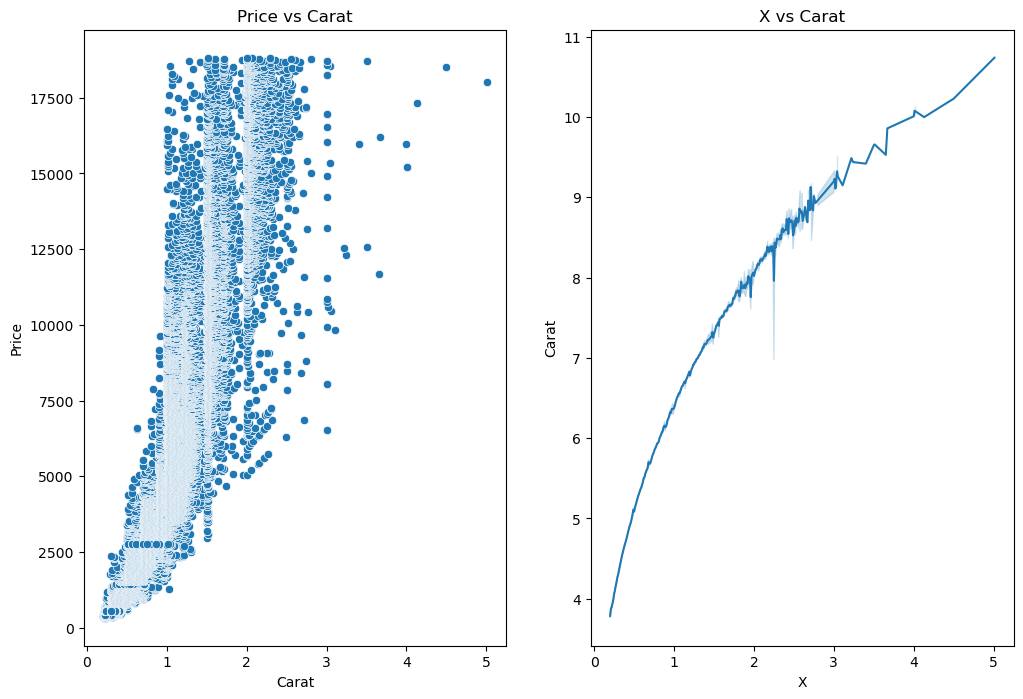

In [26]:
fig,axes=plt.subplots(1,2,figsize=(12,8))

sns.scatterplot(data=df,x='carat',y='price',ax=axes[0])
axes[0].set_title("Price vs Carat")
axes[0].set_xlabel("Carat")
axes[0].set_ylabel("Price")

sns.lineplot(data=df,x='carat',y='x',ax=axes[1])
axes[1].set_title("X vs Carat")
axes[1].set_xlabel("X")
axes[1].set_ylabel("Carat")



<Axes: xlabel='combination', ylabel='carat'>

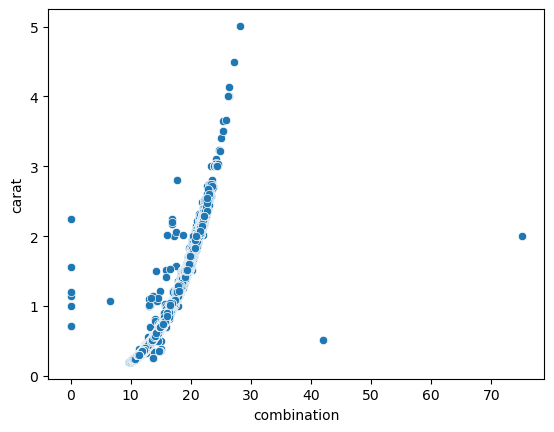

In [27]:
# feature engineering
df['combination']=df['x']+df['y']+df['z']

sns.scatterplot(data=df,x='combination',y='carat')

In [28]:
df.head(5)

,carat,cut,color,clarity,depth,table,price,x,y,z,combination
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43,10.36
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31,10.04
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31,10.43
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63,11.06
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75,11.44


<Axes: xlabel='color', ylabel='price'>

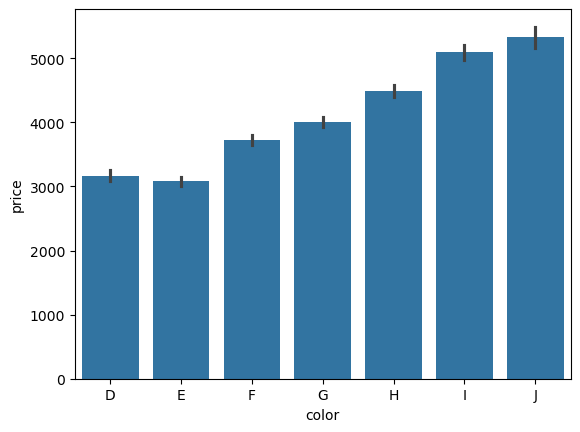

In [32]:
sns.barplot(data=df,x='color',y='price')

In [33]:
df['clarity'].unique()

['SI2', 'SI1', 'VS1', 'VS2', 'VVS2', 'VVS1', 'I1', 'IF']
Categories (8, object): ['IF', 'VVS1', 'VVS2', 'VS1', 'VS2', 'SI1', 'SI2', 'I1']

<Axes: xlabel='clarity', ylabel='price'>

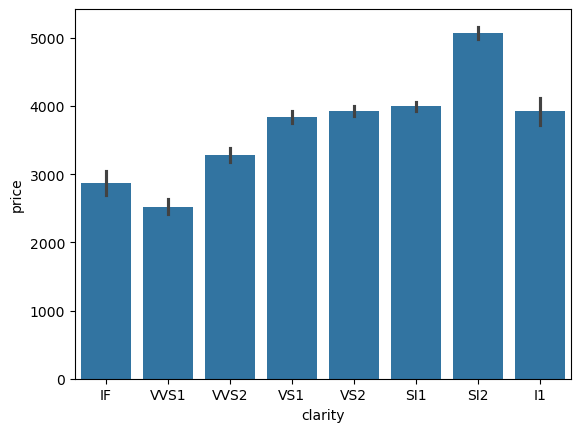

In [34]:
sns.barplot(data=df,x='clarity',y='price')

In [45]:
numeric_col=df.select_dtypes(include='number').columns.tolist()
x=df.drop(['carat','x','y','z'],axis=1)
x=pd.get_dummies(x,columns=['cut','color','clarity'],drop_first=True)
y=df['carat']

x_train,x_test,y_train,y_test=train_test_split(
    x,
    y,
    test_size=.3,
    random_state=42
)
scale=StandardScaler()
x_train[['depth','table','price','combination']]=scale.fit_transform(x_train[['depth','table','price','combination']])
x_test[['depth','table','price','combination']]=scale.transform(x_test[['depth','table','price','combination']])

In [48]:


def model_training(model,x_train,x_test,y_train,y_test):
    model.fit(x_train,y_train)
    print('model score:',model.score(x_train,y_train))

    y_pred=model.predict(x_test)
    print('model testing score:',model.score(x_test,y_test))
    print('mse:',mean_squared_error(y_test,y_pred))
    print('rmse:',root_mean_squared_error(y_test,y_pred))

In [ ]:
# base line model- Linear Regression
